正在计算 4 个 Wigner 矩阵及其投影，请稍候...
图像已保存为高清矢量图：Wigner_2D_catalysis.pdf


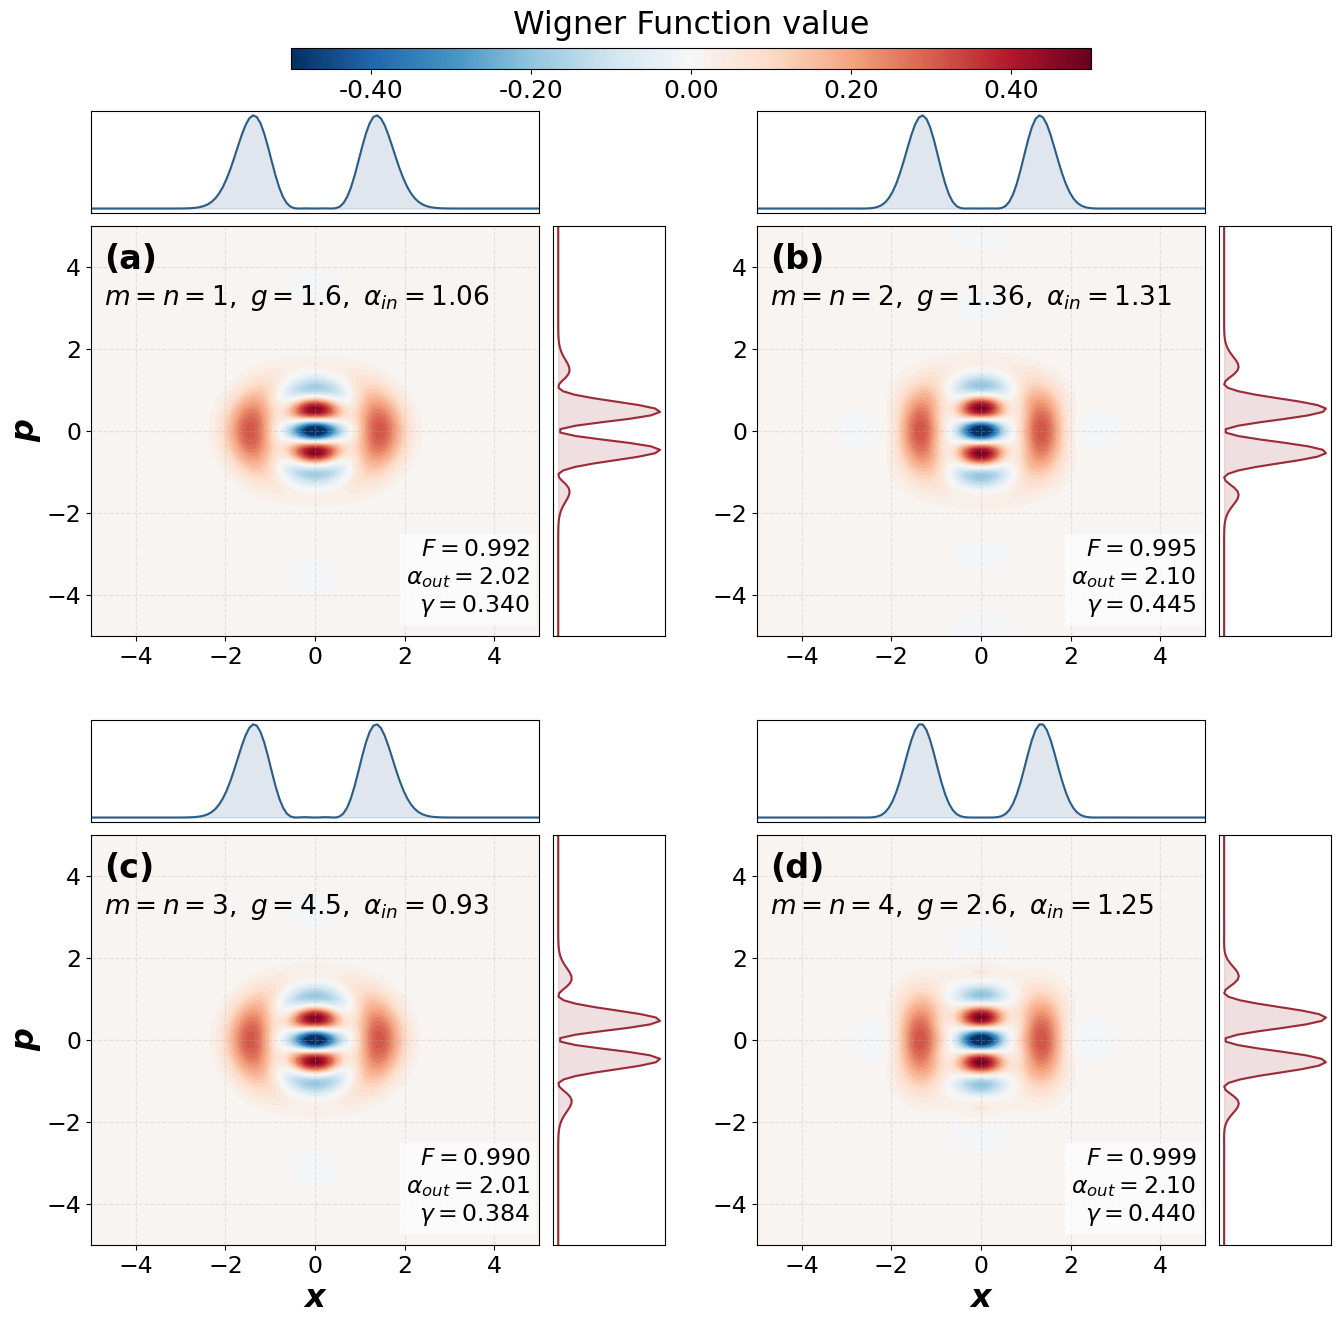

In [1]:
import numpy as np
import qutip as qt
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib import gridspec
from matplotlib.cm import ScalarMappable
from math import factorial

# ============================================================
#  --- 字体与排版参数设置区 (请在这里统一调整大小) ---
# ============================================================
FIG_SIZE = (16, 14)          # 画布整体物理尺寸 (宽, 高)
LABEL_SIZE = 23              # x, p 坐标轴标签大小
TICK_SIZE = 17               # 主图坐标轴数字刻度大小
SUBPLOT_LABEL_SIZE = 24      # (a)(b)(c)(d) 角标字体大小
CASE_LABEL_SIZE = 19         # 左上角物理参数 (m=, n=, g=...) 文本大小
EXTRA_INFO_SIZE = 17         # 右上角额外信息 (F=, alpha_out=...) 文本框大小
CBAR_TITLE_SIZE = 22         # 顶部色条标题大小
CBAR_TICK_SIZE = 18          # 顶部色条数字刻度大小
# ============================================================

# ============================================================
#  参数设置
# ============================================================
N_DIM = 30
CAT_TYPE = "odd"
XVEC = np.linspace(-5, 5, 120)
PVEC = np.linspace(-5, 5, 120)
X, P = np.meshgrid(XVEC, PVEC)

cases = [
     {
        'label': r'$m=n=1,\ g=1.6,\ \alpha_{in}=1.06$', 
        'n': 1, 'g': 1.6, 'alpha_in': 1.058,
        'extra_info': '$F=0.992$\n$\\alpha_{out}= 2.02$\n$\\gamma=0.340$' 
    },
    {
        'label': r'$m=n=2,\ g=1.36,\ \alpha_{in}=1.31$', 
        'n': 2, 'g': 1.36, 'alpha_in': 1.31,
        'extra_info': '$F=0.995$\n$\\alpha_{out}=2.10$\n$\\gamma=0.445$'
    },
    {
        'label': r'$m=n=3,\ g=4.5,\ \alpha_{in}=0.93$', 
        'n': 3, 'g': 4.5, 'alpha_in': 0.93,
        'extra_info': '$F=0.990$\n$\\alpha_{out}=2.01$\n$\\gamma=0.384$'
    },
    {
        'label': r'$m=n=4,\ g=2.6,\ \alpha_{in}=1.25$', 
        'n': 4, 'g': 2.6, 'alpha_in': 1.25,
        'extra_info': '$F=0.999$\n$\\alpha_{out}=2.10$\n$\\gamma=0.440$'
    },
]

# ============================================================
#  工具函数
# ============================================================
def precompute_input_terms(alpha_in, n, cat_type, N_dim):
    a = qt.destroy(N_dim)
    adag = qt.create(N_dim)
    alpha_plus  = qt.coherent(N_dim, alpha_in)
    alpha_minus = qt.coherent(N_dim, -alpha_in)
    phi_in = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
             else (alpha_plus - alpha_minus).unit()
    phi_vec  = phi_in.full().flatten()
    a_mat    = a.full()
    adag_mat = adag.full()
    ak_phi_vecs = [phi_vec.copy()]
    vec = phi_vec.copy()
    for _ in range(1, n + 1):
        vec = a_mat @ vec
        ak_phi_vecs.append(vec.copy())
    fac_coefs = [
        (-1)**k * factorial(n) / (factorial(k)**2 * factorial(n - k))
        for k in range(n + 1)
    ]
    return ak_phi_vecs, adag_mat, fac_coefs

def fast_catalysis_vec(g, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim):
    G = np.sqrt(max(1 - 1.0 / g**2, 0.0))
    g_diag = g ** (-np.arange(N_dim, dtype=float))
    psi_out = np.zeros(N_dim, dtype=complex)
    for k in range(n + 1):
        vec = g_diag * ak_phi_vecs[k]
        for _ in range(k):
            vec = adag_mat @ vec
        psi_out += fac_coefs[k] * (G**(2*k)) / (g**(n - k + 1)) * vec
    norm = np.linalg.norm(psi_out)
    return psi_out / norm if norm > 1e-15 else psi_out

def compute_output_state(alpha_in, n, g, N_dim):
    ak_phi_vecs, adag_mat, fac_coefs = precompute_input_terms(alpha_in, n, CAT_TYPE, N_dim)
    vec = fast_catalysis_vec(g, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim)
    return qt.Qobj(vec)

# ============================================================
#  计算 Wigner 函数
# ============================================================
print("正在计算 4 个 Wigner 矩阵及其投影，请稍候...")
W_outs = []
for case in cases:
    current_alpha_in = case['alpha_in']
    psi_out = compute_output_state(current_alpha_in, case['n'], case['g'], N_DIM)
    W_outs.append(qt.wigner(psi_out, XVEC, PVEC, g=2))

Wigner_list = W_outs

# 将色条范围限制在 -0.5 到 0.5 (用于标准化色谱映射)
norm = Normalize(vmin=-0.5, vmax=0.5)

# ============================================================
#  二维 Wigner 图及投影逻辑
# ============================================================
fig = plt.figure(figsize=FIG_SIZE) 

outer_gs = gridspec.GridSpec(
    2, 2,
    wspace=0.16,
    hspace=0.16,
    top=0.92
)

base_labels = [case['label'] for case in cases]

for idx, (W, label) in enumerate(zip(Wigner_list, base_labels)):

    W_x_proj = np.trapz(W, PVEC, axis=0)
    W_p_proj = np.trapz(W, XVEC, axis=1)

    inner_gs = gridspec.GridSpecFromSubplotSpec(
        2, 2,
        subplot_spec=outer_gs[idx],
        width_ratios=[4, 1],
        height_ratios=[1, 4],
        hspace=0.05,
        wspace=0.05
    )

    # =====================================
    # x 投影
    # =====================================
    ax_top = fig.add_subplot(inner_gs[0, 0])
    ax_top.plot(XVEC, W_x_proj, color='#2b5d87', linewidth=1.5)
    ax_top.fill_between(XVEC, W_x_proj, 0, color='#2b5d87', alpha=0.15)
    ax_top.set_xlim(-5, 5)
    ax_top.set_xticks([])
    ax_top.set_yticks([])
    ax_top.grid(True, linestyle='--', alpha=0.3)

    # =====================================
    # 主图
    # =====================================
    ax_main = fig.add_subplot(inner_gs[1, 0])
    contour = ax_main.contourf(
        XVEC, PVEC, W,
        levels=60,
        cmap='RdBu_r',
        norm=norm
    )

    ax_main.set_xlim(-5, 5)
    ax_main.set_ylim(-5, 5)
    
    # 应用自定义坐标轴标签大小
   # ★ 更改：仅在下侧 (idx=2, 3) 显示 x，仅在左侧 (idx=0, 2) 显示 p
    if idx in [2, 3]:
        ax_main.set_xlabel('x', fontsize=LABEL_SIZE, fontweight='bold', fontstyle='italic')
    else:
        ax_main.set_xlabel('')

    if idx in [0, 2]:
        ax_main.set_ylabel('p', fontsize=LABEL_SIZE, fontweight='bold', fontstyle='italic')
    else:
        ax_main.set_ylabel('')
    
    # 应用自定义刻度数字大小
    ax_main.tick_params(labelsize=TICK_SIZE)
    # 你也可以在这里取消下面两行的注释，只显示特定的刻度
    # ax_main.set_xticks([-5, 0, 5])
    # ax_main.set_yticks([-5, 0, 5])

    # 应用自定义角标大小
    subplot_label = f"({chr(97 + idx)})"
    ax_main.text(0.03, 0.96, subplot_label, transform=ax_main.transAxes, 
                 fontsize=SUBPLOT_LABEL_SIZE, fontweight='bold', va='top', ha='left')

    # 应用自定义左上角物理参数标签大小
    ax_main.text(0.03, 0.86, label, transform=ax_main.transAxes,
                 fontsize=CASE_LABEL_SIZE, weight='bold', va='top', ha='left')

    # 应用自定义右上角参数框大小
    ax_main.text(
        4.8, -4.6, cases[idx]['extra_info'],
        fontsize=EXTRA_INFO_SIZE,
        ha='right', va='bottom',
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.7)
    )

    ax_main.grid(True, linestyle='--', alpha=0.3)

    # =====================================
    # p 投影
    # =====================================
    ax_right = fig.add_subplot(inner_gs[1, 1])
    ax_right.plot(W_p_proj, PVEC, color='#9a2b37', linewidth=1.5)
    ax_right.fill_betweenx(PVEC, 0, W_p_proj, color='#9a2b37', alpha=0.15)
    ax_right.set_ylim(-5, 5)
    ax_right.set_xticks([])
    ax_right.set_yticks([])
    ax_right.grid(True, linestyle='--', alpha=0.3)

# ============================================================
# Colorbar 调整
# ============================================================
sm = ScalarMappable(norm=norm, cmap='RdBu_r')
sm.set_array([])

cbar_ax = fig.add_axes([0.25, 0.95, 0.5, 0.015])
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')

# 应用自定义色条标题大小
cbar.set_label("Wigner Function value", fontsize=23, labelpad=10, loc='center')
cbar.ax.xaxis.set_label_position('top')

tick_vals = np.linspace(-0.4, 0.4, 5)
cbar.set_ticks(tick_vals)
cbar.set_ticklabels([f"{v:.2f}" for v in tick_vals])

# 应用自定义色条刻度大小
cbar.ax.tick_params(labelsize=CBAR_TICK_SIZE)

# ============================================================
# 渲染与导出
# ============================================================
# 导出为无损矢量 PDF，完美适配 LyX
plt.savefig('Wigner_2D_catalysis.pdf', format='pdf', bbox_inches='tight')
print("图像已保存为高清矢量图：Wigner_2D_catalysis.pdf")

plt.show()